In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [2]:
dataset = pd.read_csv("Electric_Cleaned_DataSet.csv")

In [3]:
df = dataset.copy()

##  Dataset Understanding

In [4]:
df.head()

,Brand,Model,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Imputed,Rating_Clean
0,TVS,TVS iQube,3.7,916.0,119450,82.0,212,5.3,False,3.7
1,Bajaj,Bajaj Chetak,3.7,774.0,120236,80.0,153,3.5,False,3.7
2,Ather,Ather Konarc,4.8,54.0,101209,70.0,161,3.5,False,4.8
3,TVS,TVS Orbiter,4.4,201.0,102434,68.0,158,3.1,False,4.4
4,Ather,Ather Rizta,4.4,406.0,121178,80.0,160,3.5,False,4.4


In [5]:
df.describe()

,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Clean
count,108.000000,108.000000,1.080000e+02,108.000000,108.000000,108.000000,91.000000
mean,3.902315,76.083333,1.402175e+05,76.055556,155.935185,3.568852,3.894505
std,0.633688,147.301466,1.483330e+05,32.892798,86.193574,2.217133,0.660027
min,2.300000,0.000000,5.499900e+04,25.000000,60.000000,0.600000,2.300000
25%,3.400000,7.000000,8.902000e+04,57.250000,100.000000,2.275000,3.400000
50%,4.100000,23.500000,1.124965e+05,70.000000,145.000000,3.240000,4.100000
75%,4.400000,58.250000,1.477402e+05,94.250000,170.250000,4.075000,4.400000
max,4.900000,916.000000,1.525000e+06,194.000000,579.000000,16.000000,4.900000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            108 non-null    object 
 1   Model            108 non-null    object 
 2   Rating           108 non-null    float64
 3   Rating_Members   108 non-null    float64
 4   Price(Rs)        108 non-null    int64  
 5   Top_Speed(kmph)  108 non-null    float64
 6   Range(km)        108 non-null    int64  
 7   Battery(kwh)     108 non-null    float64
 8   Rating_Imputed   108 non-null    bool   
 9   Rating_Clean     91 non-null     float64
dtypes: bool(1), float64(5), int64(2), object(2)
memory usage: 7.8+ KB


In [7]:
df.shape

(108, 10)

In [8]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean'],
      dtype='object')

In [9]:
df.select_dtypes(include = "number")

,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Clean
0,3.7,916.0,119450,82.0,212,5.3,3.7
1,3.7,774.0,120236,80.0,153,3.5,3.7
2,4.8,54.0,101209,70.0,161,3.5,4.8
3,4.4,201.0,102434,68.0,158,3.1,4.4
4,4.4,406.0,121178,80.0,160,3.5,4.4
...,...,...,...,...,...,...,...
103,4.5,0.0,84993,55.0,98,2.3,NaN
104,4.1,0.0,89998,65.0,120,3.0,NaN
105,4.1,1.0,95009,60.0,105,2.2,NaN
106,4.8,4.0,134999,70.0,156,4.0,4.8


In [10]:
df.select_dtypes(include = "object")

,Brand,Model
0,TVS,TVS iQube
1,Bajaj,Bajaj Chetak
2,Ather,Ather Konarc
3,TVS,TVS Orbiter
4,Ather,Ather Rizta
...,...,...
103,Lectrix,Lectrix LXS 2.0
104,Quantum Energy,Quantum Energy Plasma
105,Quantum Energy,Quantum Energy Bziness
106,Numeros,Numeros Diplos


##  Outlier Analysis 

In [11]:
df.select_dtypes(include="number").columns.to_list()

['Rating',
 'Rating_Members',
 'Price(Rs)',
 'Top_Speed(kmph)',
 'Range(km)',
 'Battery(kwh)',
 'Rating_Clean']

In [12]:
df.head(5)

,Brand,Model,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Imputed,Rating_Clean
0,TVS,TVS iQube,3.7,916.0,119450,82.0,212,5.3,False,3.7
1,Bajaj,Bajaj Chetak,3.7,774.0,120236,80.0,153,3.5,False,3.7
2,Ather,Ather Konarc,4.8,54.0,101209,70.0,161,3.5,False,4.8
3,TVS,TVS Orbiter,4.4,201.0,102434,68.0,158,3.1,False,4.4
4,Ather,Ather Rizta,4.4,406.0,121178,80.0,160,3.5,False,4.4


In [13]:
col = "Price(Rs)"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3-q1
lower_bound = q1 - iqr*1.5
upper_bound = q3 + iqr*1.5
df[(df[col] < lower_bound)|( df[col] > upper_bound)].sort_values(by=col)

,Brand,Model,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Imputed,Rating_Clean
62,Raptee,Raptee HV T30,3.3,9.0,239000,135.0,200,5.40,False,3.3
36,Simple,Simple Ultra,3.8,14.0,244999,115.0,400,6.50,False,3.8
29,Ultraviolette,Ultraviolette X47 Crossover,4.2,38.0,249000,145.0,323,10.30,False,4.2
39,TVS,TVS X,3.7,26.0,264855,105.0,140,4.40,False,3.7
26,Royal Enfield,Royal Enfield Flying Flea C6,3.3,20.0,279000,115.0,154,3.91,False,3.3
45,Yamaha,Yamaha Aerox E,4.7,0.0,281610,95.5,117,3.00,True,NaN
47,Ultraviolette,Ultraviolette F77 SuperStreet,4.4,8.0,308987,155.0,323,10.30,False,4.4
34,Ultraviolette,Ultraviolette F77 Mach 2,4.7,43.0,308994,155.0,323,10.30,False,4.7
41,BMW,BMW CE 02,3.9,10.0,449900,95.0,108,3.90,False,3.9
57,BMW,BMW CE 04,3.9,5.0,1525000,120.0,130,8.90,True,NaN


In [14]:
col = "Top_Speed(kmph)"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3-q1
lower_bound = q1 - iqr*1.5
upper_bound = q3 + iqr*1.5
df[(df[col] < lower_bound)|( df[col] > upper_bound)].sort_values(by=col)

,Brand,Model,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Imputed,Rating_Clean
34,Ultraviolette,Ultraviolette F77 Mach 2,4.7,43.0,308994,155.0,323,10.3,False,4.7
47,Ultraviolette,Ultraviolette F77 SuperStreet,4.4,8.0,308987,155.0,323,10.3,False,4.4
17,OLA,OLA Roadster Pro,4.8,131.0,199999,194.0,579,16.0,False,4.8


In [15]:
col = "Range(km)"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3-q1
lower_bound = q1 - iqr*1.5
upper_bound = q3 + iqr*1.5
df[(df[col] < lower_bound)|( df[col] > upper_bound)].sort_values(by=col)

,Brand,Model,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Imputed,Rating_Clean
12,OLA,OLA S1 Z,4.10,15.0,79999,70.0,301,5.1,False,4.1
8,OLA,OLA S1 X,4.25,320.0,89999,125.0,320,5.2,True,NaN
20,OLA,OLA S1 Pro,3.10,241.0,135846,141.0,320,5.2,False,3.1
29,Ultraviolette,Ultraviolette X47 Crossover,4.20,38.0,249000,145.0,323,10.3,False,4.2
34,Ultraviolette,Ultraviolette F77 Mach 2,4.70,43.0,308994,155.0,323,10.3,False,4.7
47,Ultraviolette,Ultraviolette F77 SuperStreet,4.40,8.0,308987,155.0,323,10.3,False,4.4
36,Simple,Simple Ultra,3.80,14.0,244999,115.0,400,6.5,False,3.8
23,OLA,OLA Roadster X Plus,4.10,48.0,129152,125.0,501,9.1,False,4.1
17,OLA,OLA Roadster Pro,4.80,131.0,199999,194.0,579,16.0,False,4.8


In [16]:
col = "Battery(kwh)"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)
iqr = q3-q1
lower_bound = q1 - iqr*1.5
upper_bound = q3 + iqr*1.5
df[(df[col] < lower_bound)|( df[col] > upper_bound)].sort_values(by=col)

,Brand,Model,Rating,Rating_Members,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh),Rating_Imputed,Rating_Clean
57,BMW,BMW CE 04,3.9,5.0,1525000,120.0,130,8.9,True,NaN
23,OLA,OLA Roadster X Plus,4.1,48.0,129152,125.0,501,9.1,False,4.1
29,Ultraviolette,Ultraviolette X47 Crossover,4.2,38.0,249000,145.0,323,10.3,False,4.2
34,Ultraviolette,Ultraviolette F77 Mach 2,4.7,43.0,308994,155.0,323,10.3,False,4.7
47,Ultraviolette,Ultraviolette F77 SuperStreet,4.4,8.0,308987,155.0,323,10.3,False,4.4
17,OLA,OLA Roadster Pro,4.8,131.0,199999,194.0,579,16.0,False,4.8


## Feature Engineering

In [17]:
df['Price_Segment'] = pd.qcut(df['Price(Rs)'], 3, labels=['Budget', 'Mid', 'Premium'])
df["Range_Segment"] = pd.qcut(df["Range(km)"], q=3, labels=["Low", "Medium", "High"])
df["Battery_Segment"] = pd.qcut(df["Battery(kwh)"] , 3 , labels = ["Low", "Medium", "High"])
df["Speed_Segment"]  = pd.qcut(df["Top_Speed(kmph)"], 3 , labels = ["Low","Medium","High"])

## Exploratory Data Analysis & Visualization

In [18]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

In [19]:
df.dtypes

Brand                object
Model                object
Rating              float64
Rating_Members      float64
Price(Rs)             int64
Top_Speed(kmph)     float64
Range(km)             int64
Battery(kwh)        float64
Rating_Imputed         bool
Rating_Clean        float64
Price_Segment      category
Range_Segment      category
Battery_Segment    category
Speed_Segment      category
dtype: object

## Univariate Analysis

### Price(Rs)

In [20]:
df["Price(Rs)"].isna().sum()

np.int64(0)

In [21]:
print("Mean of Price:- Rs ",round(df["Price(Rs)"].mean(),2),"\n")
print("Median of Price:- Rs ",round(df["Price(Rs)"].median(),2),"\n")
print("Mode of Price:- Rs\n",round(df["Price(Rs)"].mode(),2),"\n")

Mean of Price:- Rs  140217.52 

Median of Price:- Rs  112496.5 

Mode of Price:- Rs
 0    79999
Name: Price(Rs), dtype: int64 



In [22]:
col = "Price(Rs)"

data = df[col].dropna()

price_min , price_max  = data.min(),data.max()
price_range = price_max-price_min
variance = data.var()
std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3-q1

dispersion = pd.DataFrame({
    'Measure' : ["Minimum","Maximum","Range","Variance","Std Deviation","Q1(25%)","Q3(75%)","IQR"],
    'Value' : [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})

dispersion["Value"] = dispersion["Value"].apply(lambda v : f'{v:,.2f}')
dispersion


,Measure,Value
0,Minimum,"54,999.00"
1,Maximum,"1,525,000.00"
2,Range,"1,470,001.00"
3,Variance,"22,002,684,224.10"
4,Std Deviation,"148,333.02"
5,Q1(25%),"89,020.00"
6,Q3(75%),"147,740.25"
7,IQR,"58,720.25"


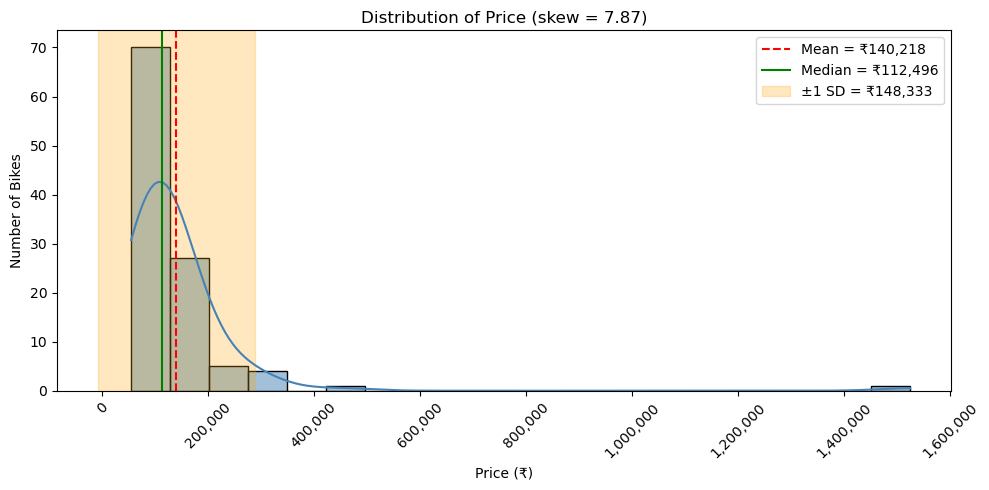

In [23]:
col = "Price(Rs)"

plt.figure(figsize=(10, 5))

sns.histplot(df[col],bins=20,kde=True,color="steelblue",edgecolor="black")
mean = df[col].mean()
median = df[col].median()
std = df[col].std()
plt.axvline(mean, color="red", linestyle="--",label=f"Mean = ₹{mean:,.0f}")
plt.axvline(median, color="green", linestyle="-",label=f"Median = ₹{median:,.0f}")
plt.axvspan(mean - std, mean + std,color="orange", alpha=0.25,label=f"±1 SD = ₹{std:,.0f}")

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.xticks(rotation=45)
plt.title(f"Distribution of Price (skew = {df[col].skew():.2f})")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Bikes")
plt.legend()
plt.tight_layout()
plt.show()

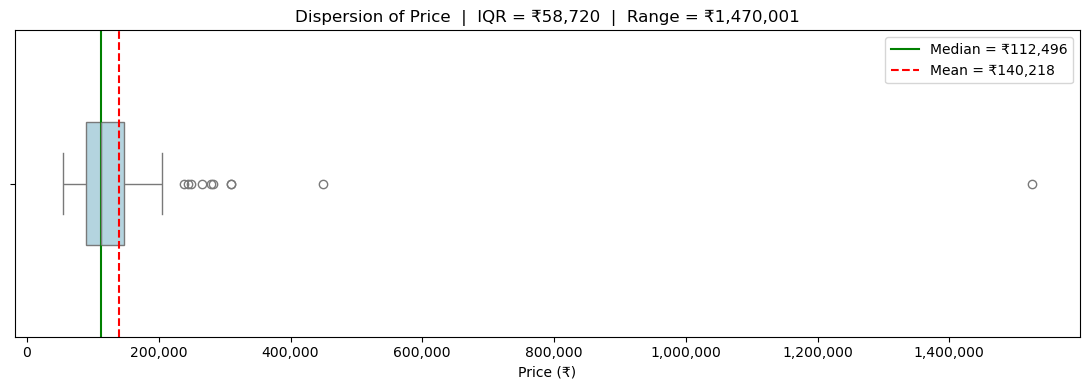

In [24]:
col = 'Price(Rs)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = ₹{df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = ₹{df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Price  |  IQR = ₹{iqr:,.0f}  |  Range = ₹{df[col].max()-df[col].min():,.0f}')
plt.xlabel('Price (₹)')
plt.legend()
plt.tight_layout()
plt.show()

### Top_Speed(kmph)

In [25]:
df["Top_Speed(kmph)"].isna().sum()

np.int64(0)

In [26]:
print("Mean of Top_Speed(kmph) ",round(df["Top_Speed(kmph)"].mean(),2),"\n")
print("Median of Top_Speed(kmph) ",round(df["Top_Speed(kmph)"].median(),2),"\n")
print("Mode of Top_Speed(kmph)\n",round(df["Top_Speed(kmph)"].mode(),2),"\n")

Mean of Top_Speed(kmph)  76.06 

Median of Top_Speed(kmph)  70.0 

Mode of Top_Speed(kmph)
 0    25.0
Name: Top_Speed(kmph), dtype: float64 



In [27]:
col = "Top_Speed(kmph)"

data = df[col].dropna()

price_min , price_max  = data.min(),data.max()
price_range = price_max-price_min
variance = data.var()
std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3-q1

dispersion = pd.DataFrame({
    'Measure' : ["Minimum","Maximum","Range","Variance","Std Deviation","Q1(25%)","Q3(75%)","IQR"],
    'Value' : [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})

dispersion["Value"] = dispersion["Value"].apply(lambda v : f'{v:,.2f}')
dispersion


,Measure,Value
0,Minimum,25.00
1,Maximum,194.00
2,Range,169.00
3,Variance,"1,081.94"
4,Std Deviation,32.89
5,Q1(25%),57.25
6,Q3(75%),94.25
7,IQR,37.00


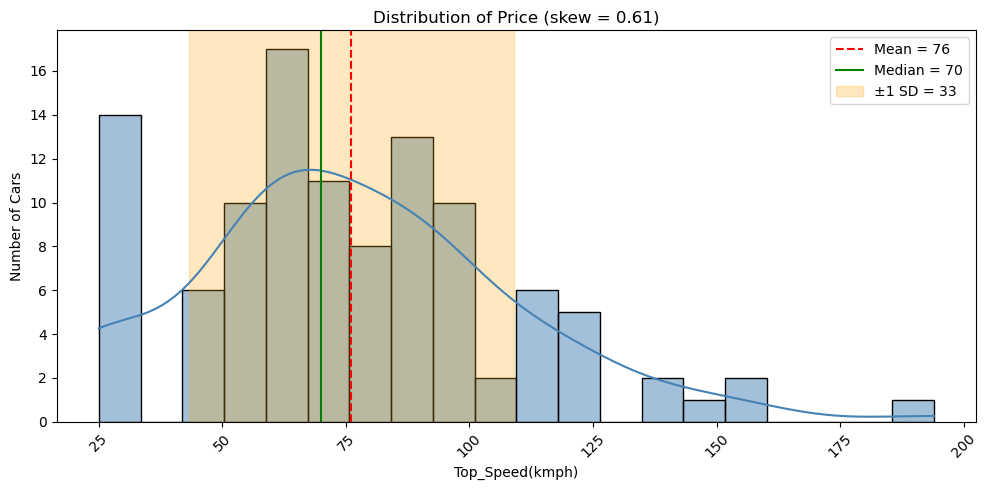

In [28]:
col = 'Top_Speed(kmph)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Price (skew = {df[col].skew():.2f})')
plt.xlabel('Top_Speed(kmph)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

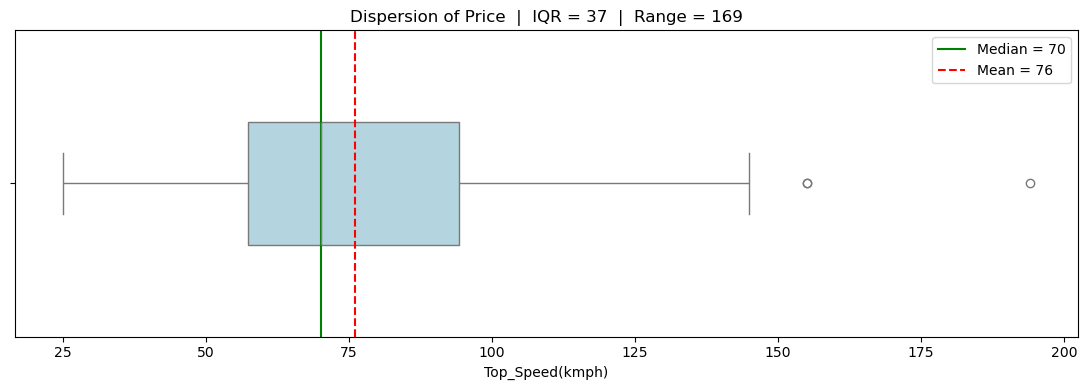

In [29]:
col = 'Top_Speed(kmph)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Price  |  IQR = {iqr:,.0f}  |  Range = {df[col].max()-df[col].min():,.0f}')
plt.xlabel('Top_Speed(kmph)')
plt.legend()
plt.tight_layout()
plt.show()

### Range(km)


In [30]:
df["Range(km)"].isna().sum()

np.int64(0)

In [31]:
print("Mean of Range(km) ",round(df["Range(km)"].mean(),2),"\n")
print("Median of Range(km) ",round(df["Range(km)"].median(),2),"\n")
print("Mode of Range(km)\n",round(df["Range(km)"].mode(),2),"\n")

Mean of Range(km)  155.94 

Median of Range(km)  145.0 

Mode of Range(km)
 0    160
Name: Range(km), dtype: int64 



In [32]:
col = 'Range(km)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,60.00
1,Maximum,579.00
2,Range,519.00
3,Variance,"7,429.33"
4,Standard Deviation,86.19
5,Q1 (25%),100.00
6,Q3 (75%),170.25
7,IQR,70.25


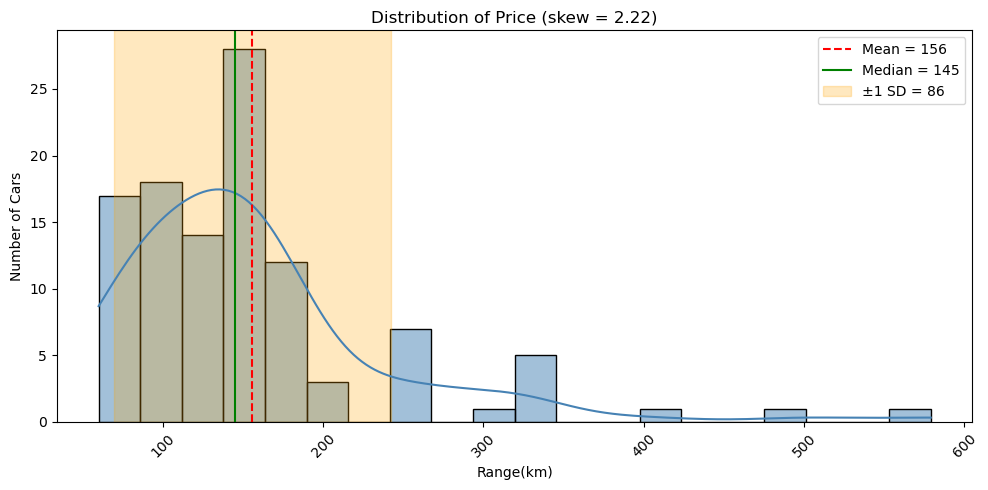

In [33]:
col = 'Range(km)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Price (skew = {df[col].skew():.2f})')
plt.xlabel('Range(km)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

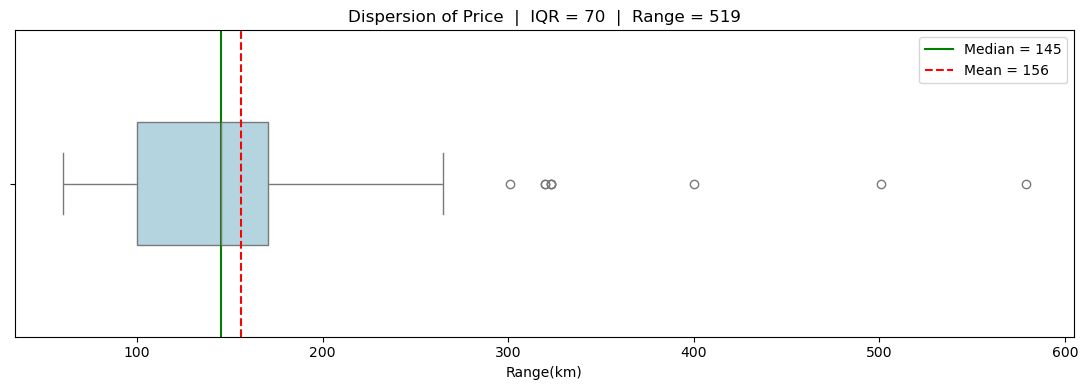

In [34]:
col = 'Range(km)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.0f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.0f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Price  |  IQR = {iqr:,.0f}  |  Range = {df[col].max()-df[col].min():,.0f}')
plt.xlabel('Range(km)')
plt.legend()
plt.tight_layout()
plt.show()

### Battery(kwh)

In [35]:
df["Battery(kwh)"].isna().sum()

np.int64(0)

In [36]:
print("Mean of Battery(kwh) ",round(df["Battery(kwh)"].mean(),2),"\n")
print("Median of Battery(kwh) ",round(df["Battery(kwh)"].median(),2),"\n")
print("Mode of Battery(kwh)\n",round(df["Battery(kwh)"].mode(),2),"\n")

Mean of Battery(kwh)  3.57 

Median of Battery(kwh)  3.24 

Mode of Battery(kwh)
 0    3.0
Name: Battery(kwh), dtype: float64 



In [37]:
col = 'Battery(kwh)'
data = df[col].dropna()

price_min, price_max = data.min(), data.max()
price_range = price_max - price_min

variance = data.var()

std_dev = data.std()

q1 = data.quantile(0.25)
q3 = data.quantile(0.75)
iqr = q3 - q1

dispersion = pd.DataFrame({
    'Measure': ['Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1 (25%)', 'Q3 (75%)', 'IQR'],
    'Value': [price_min, price_max, price_range, variance, std_dev, q1, q3, iqr]
})
dispersion['Value'] = dispersion['Value'].apply(lambda v: f'{v:,.2f}')
dispersion

,Measure,Value
0,Minimum,0.60
1,Maximum,16.00
2,Range,15.40
3,Variance,4.92
4,Standard Deviation,2.22
5,Q1 (25%),2.27
6,Q3 (75%),4.08
7,IQR,1.80


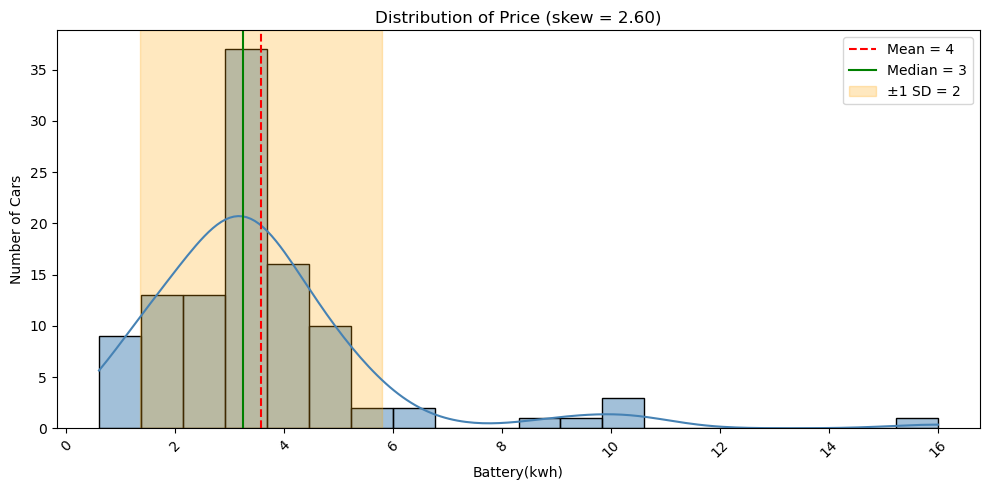

In [38]:
col = 'Battery(kwh)'

plt.figure(figsize=(10, 5))
sns.histplot(df[col], bins=20, kde=True, color='steelblue', edgecolor='black')

plt.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean = {df[col].mean():,.0f}')
plt.axvline(df[col].median(), color='green', linestyle='-', label=f'Median = {df[col].median():,.0f}')
plt.axvspan(df[col].mean() - df[col].std(), df[col].mean() + df[col].std(), color='orange', alpha=0.25,
            label=f'±1 SD = {df[col].std():,.0f}')


plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.title(f'Distribution of Price (skew = {df[col].skew():.2f})')
plt.xlabel('Battery(kwh)')
plt.ylabel('Number of Cars')
plt.legend()
plt.tight_layout()
plt.show()

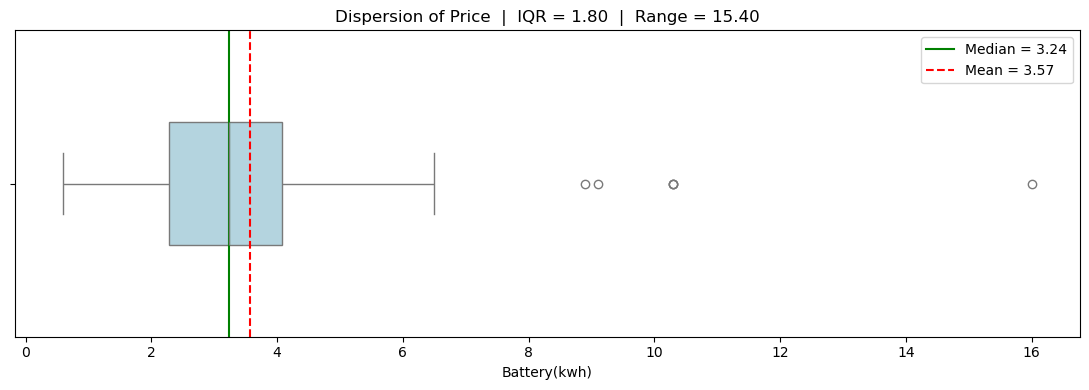

In [39]:
col = 'Battery(kwh)'
q1, q3 = df[col].quantile([0.25, 0.75])
iqr = q3 - q1

plt.figure(figsize=(11, 4))
sns.boxplot(x=df[col], color='lightblue', width=0.4)

plt.axvline(df[col].median(), color='green', ls='-', label=f'Median = {df[col].median():,.2f}')
plt.axvline(df[col].mean(), color='red', ls='--', label=f'Mean = {df[col].mean():,.2f}')

plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.title(f'Dispersion of Price  |  IQR = {iqr:,.2f}  |  Range = {df[col].max()-df[col].min():,.2f}')
plt.xlabel('Battery(kwh)')
plt.legend()
plt.tight_layout()
plt.show()

### Brand

In [40]:
col = 'Brand'   

count = df[col].value_counts()
percent = df[col].value_counts(normalize=True).mul(100)

table = pd.DataFrame({'Count': count, 'Percent (%)': percent})
table['Cumulative (%)'] = table['Percent (%)'].cumsum()
table

,Count,Percent (%),Cumulative (%)
Brand,,,
Okinawa,8,7.407407,7.407407
OLA,7,6.481481,13.888889
Odysse,6,5.555556,19.444444
Ather,5,4.629630,24.074074
PURE EV,4,3.703704,27.777778
Lectrix,4,3.703704,31.481481
Ampere,4,3.703704,35.185185
Revolt,4,3.703704,38.888889
OPG Mobility,4,3.703704,42.592593


In [41]:
print('Number of categories :', df[col].nunique())

Number of categories : 39


In [42]:
print('Most common (mode)   :', df[col].mode()[0])

Most common (mode)   : Okinawa


In [43]:
print('Least common         :', count[count == count.min()], f'({count.min()} records)')

Least common         : Brand
Matter             1
Keeway             1
Ferrato            1
Kinetic            1
Raptee             1
Suzuki             1
Royal Enfield      1
Bounce Infinity    1
River              1
Name: count, dtype: int64 (1 records)


In [44]:
print('Top category share   :', f'{percent.iloc[0]}%')

Top category share   : 7.4074074074074066%


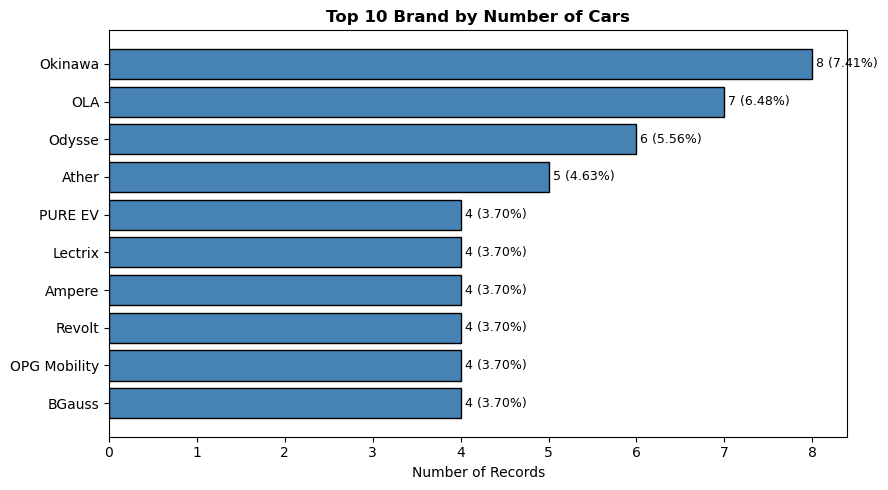

In [45]:
top = count.head(10)

plt.figure(figsize=(9, 5))
plt.barh(top.index.astype(str)[::-1], top.values[::-1], color='steelblue', edgecolor='black')

for i, (c, p) in enumerate(zip(top.values[::-1], percent.head(10).values[::-1])):
    plt.text(c, i, f' {c} ({p:.2f}%)', va='center', fontsize=9)

plt.title(f'Top 10 {col} by Number of Cars', fontweight='bold')
plt.xlabel('Number of Records')
plt.tight_layout()
plt.show()

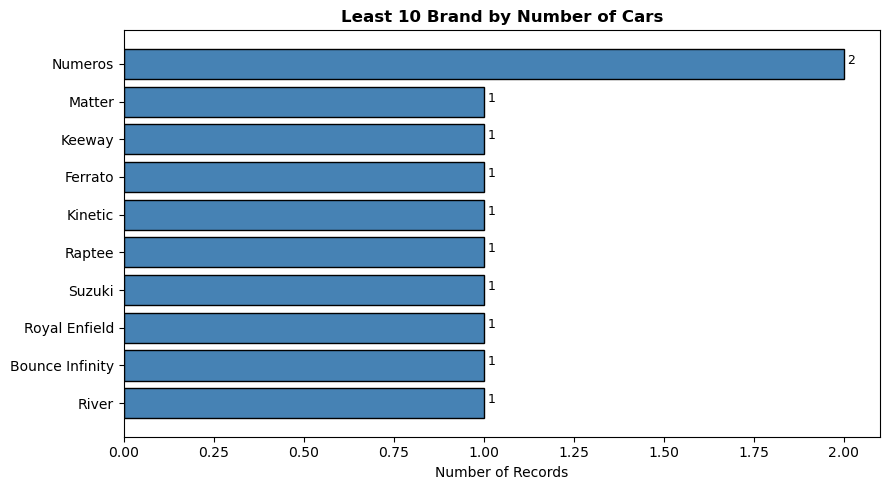

In [46]:
top = count.tail(10)

plt.figure(figsize=(9, 5))
plt.barh(top.index.astype(str)[::-1], top.values[::-1], color='steelblue', edgecolor='black')

for i, (c, p) in enumerate(zip(top.values[::-1], percent.head(10).values[::-1])):
    plt.text(c, i, f' {c} ', fontsize=9)

plt.title(f'Least 10 {col} by Number of Cars', fontweight='bold')
plt.xlabel('Number of Records')
plt.tight_layout()
plt.show()

### Model

In [47]:
df["Model"].nunique()  # each brand has only 1 model only

108

In [48]:
df.shape

(108, 14)

## Bivariate Analysis

### Numerical vs Numerical Analysis

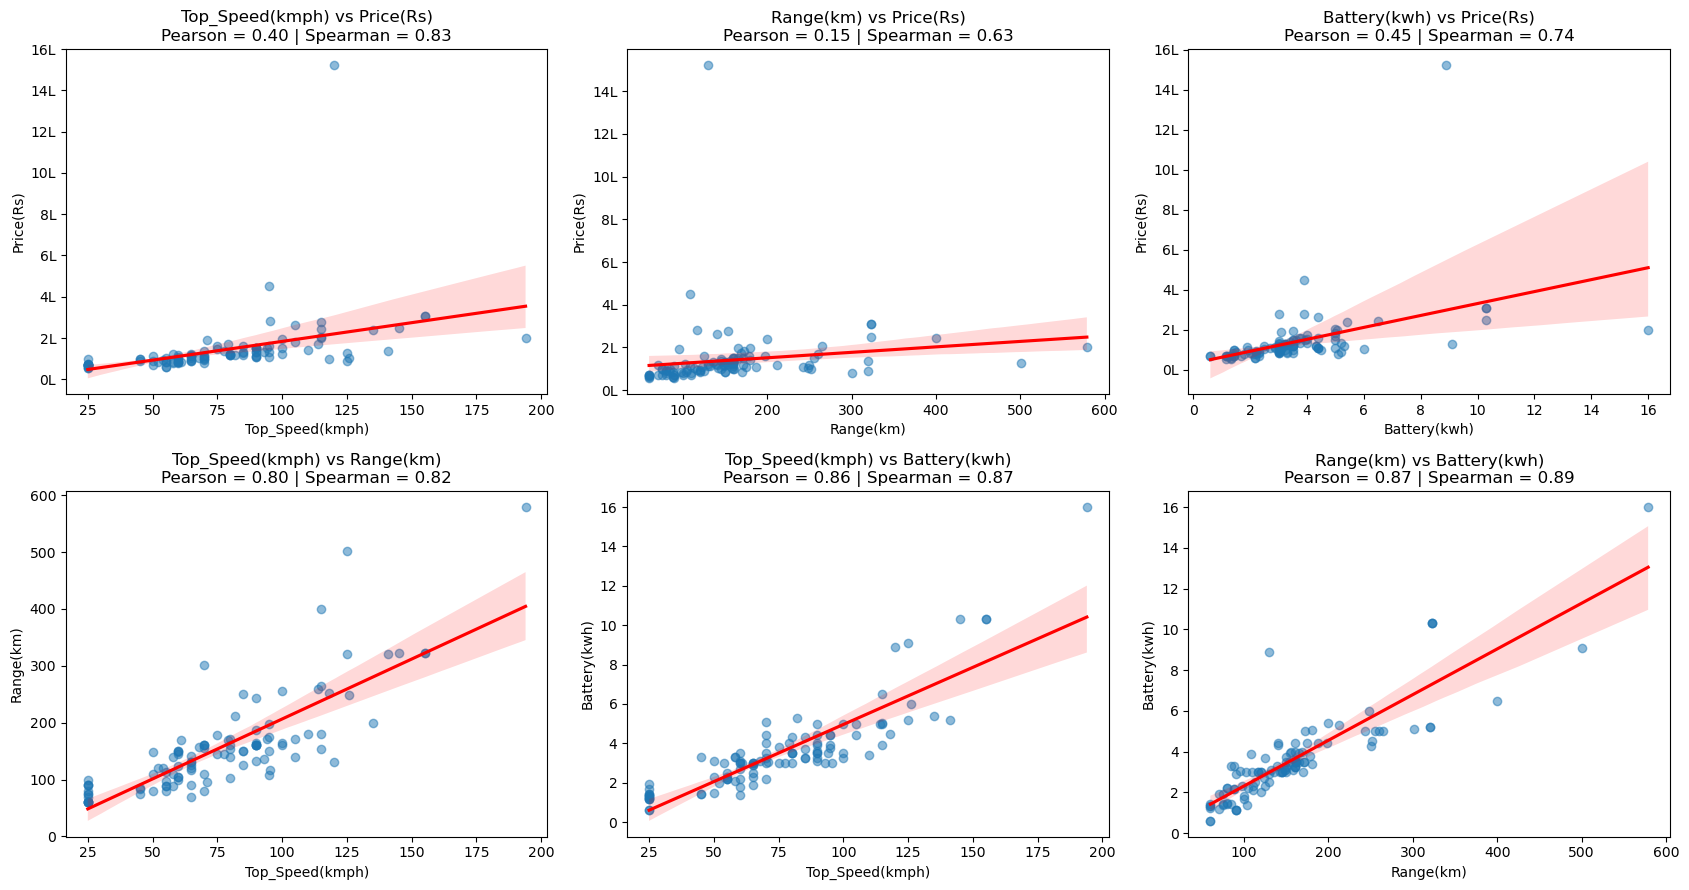

In [49]:
pairs = [( 'Top_Speed(kmph)','Price(Rs)'), ('Range(km)','Price(Rs)'),
         ('Battery(kwh)','Price(Rs)'), ('Top_Speed(kmph)', 'Range(km)'),
         ('Top_Speed(kmph)', 'Battery(kwh)'), ('Range(km)', 'Battery(kwh)')]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (x, y) in zip(axes.flatten(), pairs):
    sub = df[[x, y]].dropna()
    r = sub[x].corr(sub[y])                       # Pearson
    rho = sub[x].corr(sub[y], method='spearman')  # Spearman
    sns.regplot(data=sub, x=x, y=y, ax=ax, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
    ax.set_title(f'{x} vs {y}\nPearson = {r:.2f} | Spearman = {rho:.2f}')
    if y == 'Price(Rs)':
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e5:.0f}L'))
plt.tight_layout()
plt.show()

### Categorical vs Numerical Analysis

####  Which brands are most and least expensive?


In [50]:
df.groupby("Brand")["Price(Rs)"].median().sort_values()

Brand
Evolet              63599.0
Joy e-bike          65938.5
Yo                  69383.5
Kinetic Green       71985.0
Gemopai             79999.0
iVOOMi              82499.0
OPG Mobility        86996.0
Lectrix             88494.5
Quantum Energy      92503.5
Ampere              96999.0
Odysse             100224.5
PURE EV            102393.0
Okinawa            102930.0
OLA                104999.0
Hop Electric       109177.5
Kinetic            111499.0
Bajaj              112418.0
Bounce Infinity    115605.0
TVS                119450.0
VLF                120112.0
Honda              120133.0
Numeros            124999.0
Oben               125001.5
BGauss             128490.0
Revolt             128969.5
VIDA               130090.5
Ather              130283.0
Avore              149999.0
River              152702.0
Ferrato            159999.0
Matter             182591.0
Suzuki             190772.0
Keeway             199000.0
Simple             204999.0
Yamaha             227323.5
Raptee        

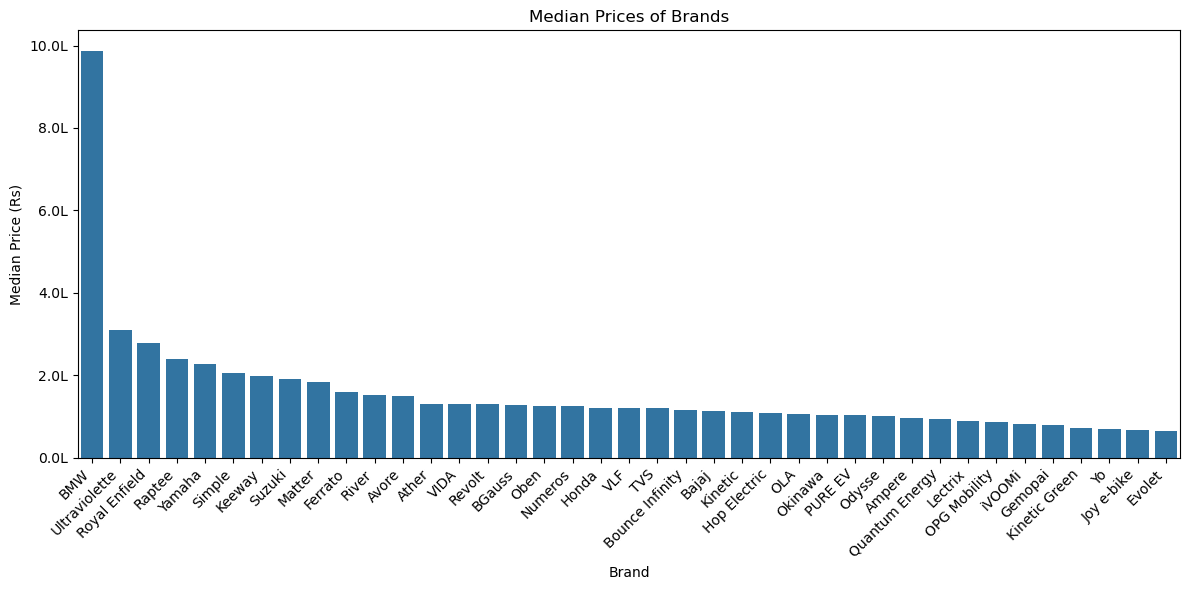

In [51]:
brand_order = (
    df.groupby("Brand")["Price(Rs)"].median().sort_values(ascending=False).index
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="Brand",
    y="Price(Rs)",
    order = brand_order,
    estimator="median",
    errorbar=None,
)

plt.title("Median Prices of Brands")
plt.xlabel("Brand")
plt.ylabel("Median Price (Rs)")
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1e5:.1f}L"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Which brands sell the most models?

In [52]:
df["Brand"].value_counts()

Brand
Okinawa            8
OLA                7
Odysse             6
Ather              5
PURE EV            4
Lectrix            4
Ampere             4
Revolt             4
OPG Mobility       4
BGauss             4
Joy e-bike         4
TVS                3
Avore              3
Gemopai            3
Ultraviolette      3
Honda              3
Simple             3
Kinetic Green      3
Hop Electric       2
Yo                 2
Evolet             2
iVOOMi             2
Quantum Energy     2
BMW                2
Bajaj              2
Oben               2
VLF                2
Yamaha             2
VIDA               2
Numeros            2
Matter             1
Keeway             1
Ferrato            1
Kinetic            1
Raptee             1
Suzuki             1
Royal Enfield      1
Bounce Infinity    1
River              1
Name: count, dtype: int64

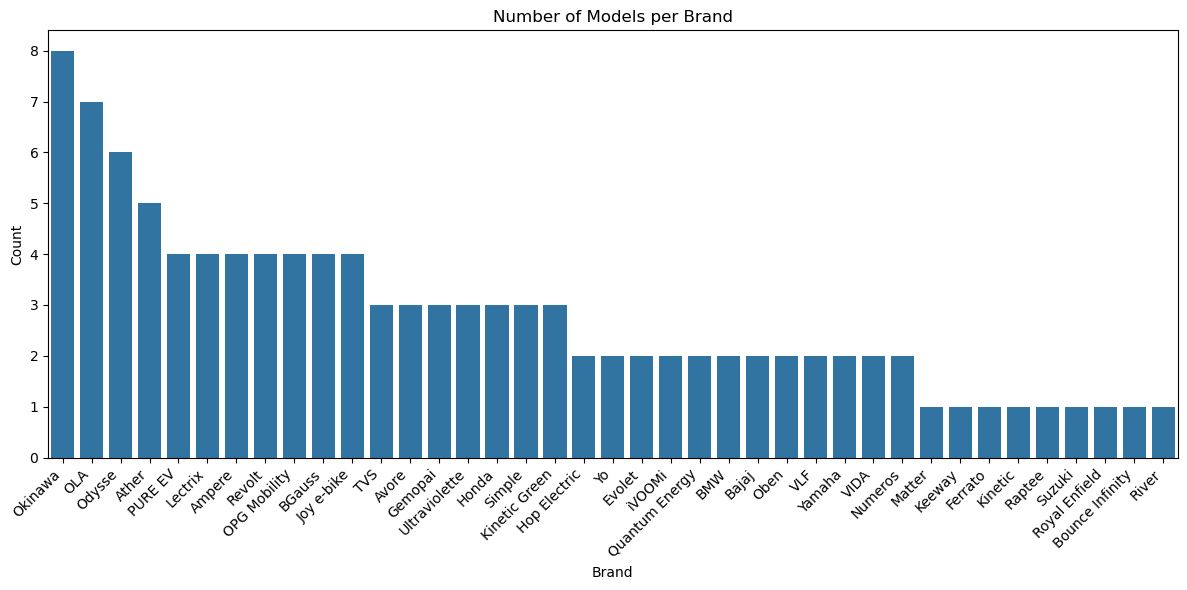

In [53]:
brand_order = df["Brand"].value_counts().index

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="Brand",
    order=brand_order,
)

plt.title("Number of Models per Brand")
plt.xlabel("Brand")
plt.ylabel("Count")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Price_Segment vs Range(km)

In [54]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

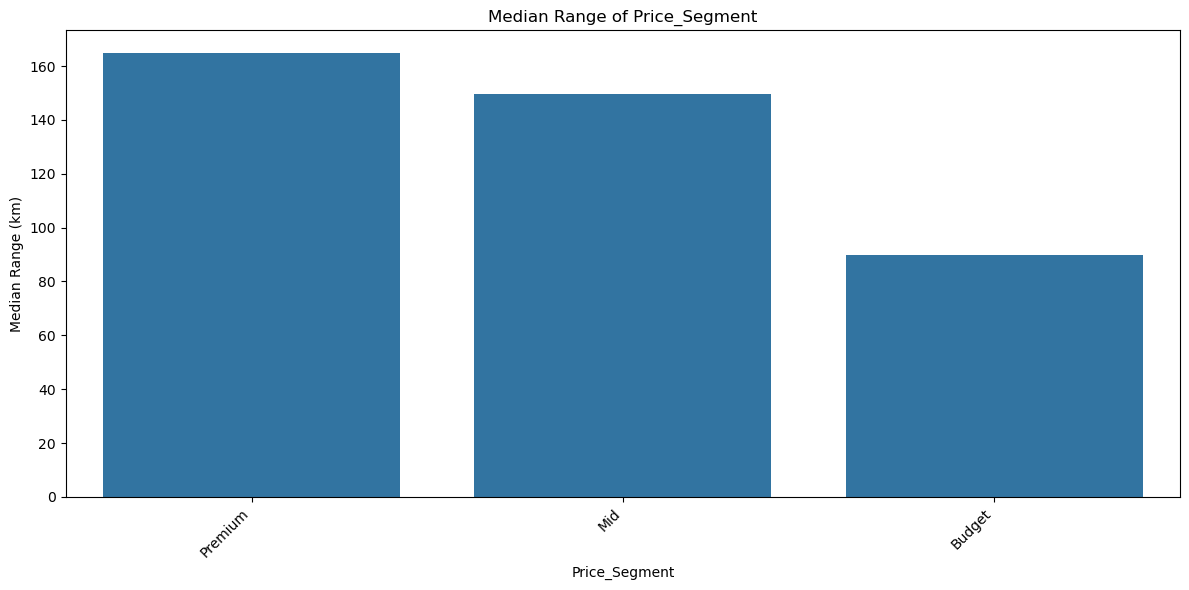

In [55]:
brand_order = (
    df.groupby("Price_Segment")["Range(km)"].median().sort_values(ascending=False).index
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="Price_Segment",
    y="Range(km)",
    order = brand_order,
    estimator="median",
    errorbar=None,
)

plt.title("Median Range of Price_Segment")
plt.xlabel("Price_Segment")
plt.ylabel("Median Range (km)")
ax = plt.gca()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Categorical vs Categorical Analysis

In [56]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

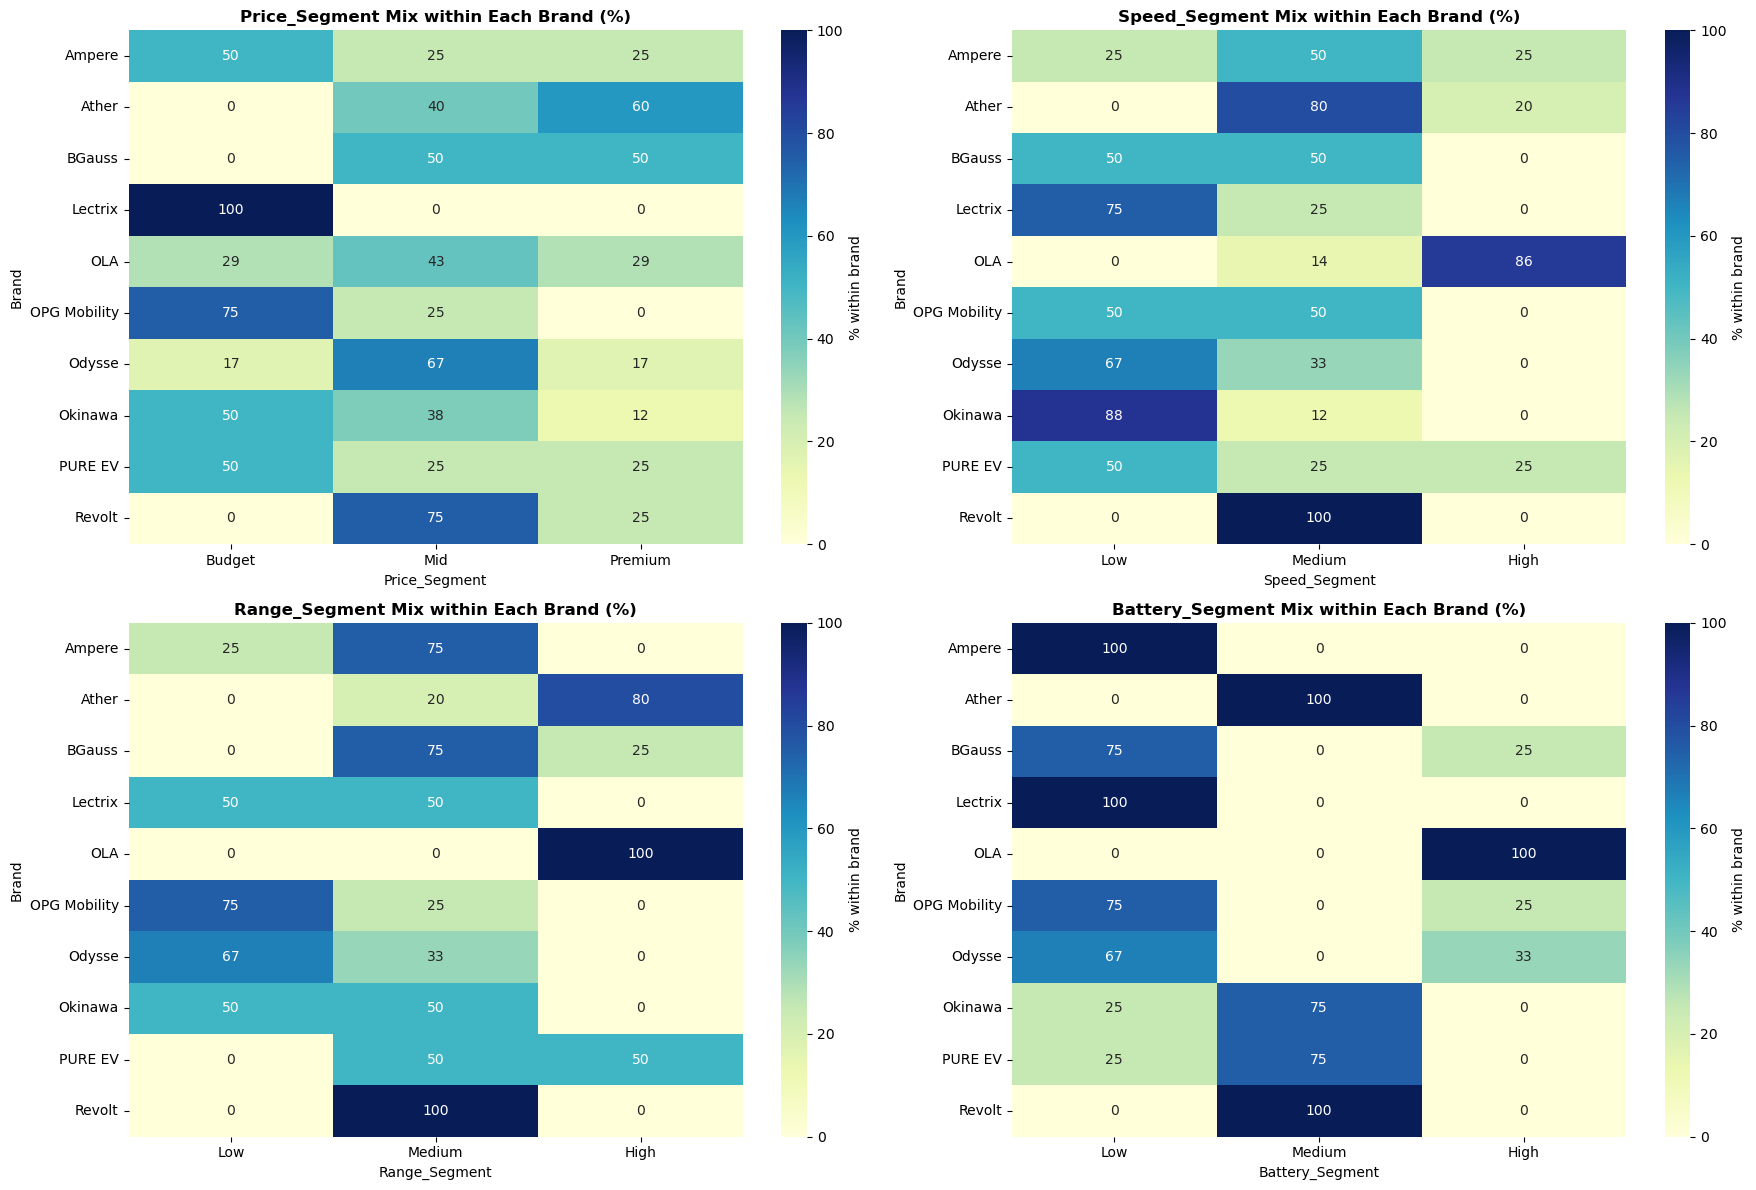

In [57]:
pairs = [
    ('Brand', 'Price_Segment'),
    ('Brand', 'Speed_Segment'),
    ('Brand', 'Range_Segment'),
    ('Brand', 'Battery_Segment')
]

top_brands = df['Brand'].value_counts().head(10).index
sub = df[df['Brand'].isin(top_brands)]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for ax, (x, y) in zip(axes.flatten(), pairs):

    data = sub[[x, y]].dropna()

    ct = pd.crosstab(
        data[x],
        data[y],
        normalize='index'
    ) * 100

    sns.heatmap(
        ct,
        annot=True,
        fmt='.0f',
        cmap='YlGnBu',
        vmin=0,
        vmax=100,
        cbar_kws={'label': '% within brand'},
        ax=ax
    )

    ax.set_title(f'{y} Mix within Each Brand (%)', fontweight='bold')
    ax.set_xlabel(y)
    ax.set_ylabel('Brand')

plt.tight_layout()
plt.show()

## Multivariate Analysis

In [58]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

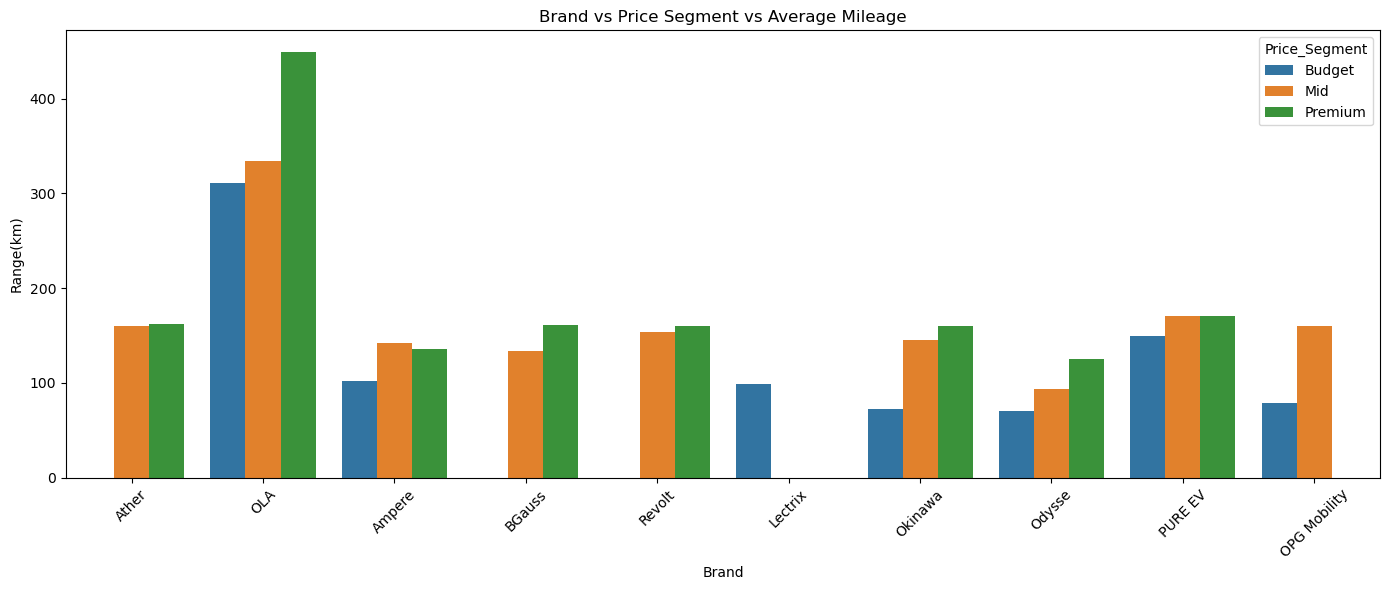

In [59]:
top_brands = df['Brand'].value_counts().head(10).index
sub = df[df['Brand'].isin(top_brands)]

plt.figure(figsize=(14, 6))

sns.barplot(
    data=sub,
    x='Brand',
    y='Range(km)',
    hue='Price_Segment',
    errorbar=None
)

plt.xticks(rotation=45)
plt.title('Brand vs Price Segment vs Average Mileage')
plt.tight_layout()
plt.show()

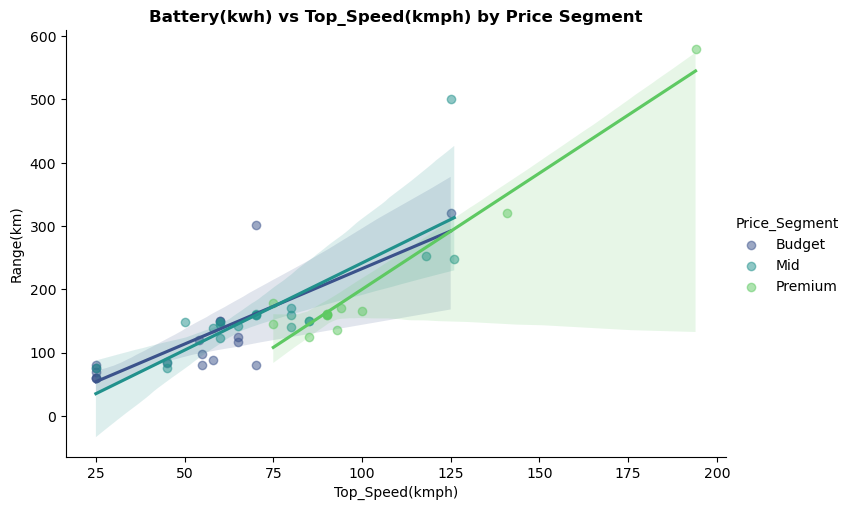

In [60]:
sns.lmplot(data=sub, x='Top_Speed(kmph)', y='Range(km)', hue='Price_Segment',
           palette='viridis', height=5, aspect=1.5, scatter_kws={'alpha': 0.5})
plt.title('Battery(kwh) vs Top_Speed(kmph) by Price Segment', fontweight='bold')
plt.show()

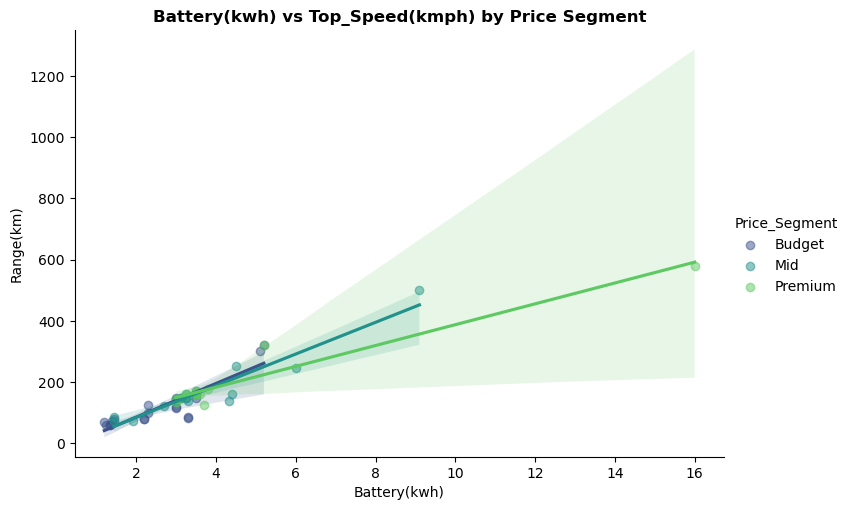

In [61]:
sns.lmplot(data=sub, x='Battery(kwh)', y='Range(km)', hue='Price_Segment',
           palette='viridis', height=5, aspect=1.5, scatter_kws={'alpha': 0.5})
plt.title('Battery(kwh) vs Top_Speed(kmph) by Price Segment', fontweight='bold')
plt.show()

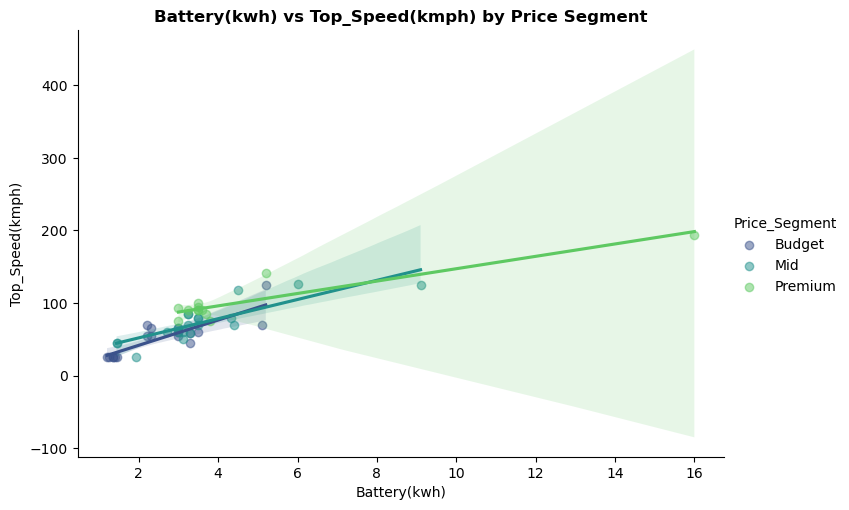

In [62]:
sns.lmplot(data=sub, x='Battery(kwh)', y='Top_Speed(kmph)', hue='Price_Segment',
           palette='viridis', height=5, aspect=1.5, scatter_kws={'alpha': 0.5})
plt.title('Battery(kwh) vs Top_Speed(kmph) by Price Segment', fontweight='bold')
plt.show()

In [63]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

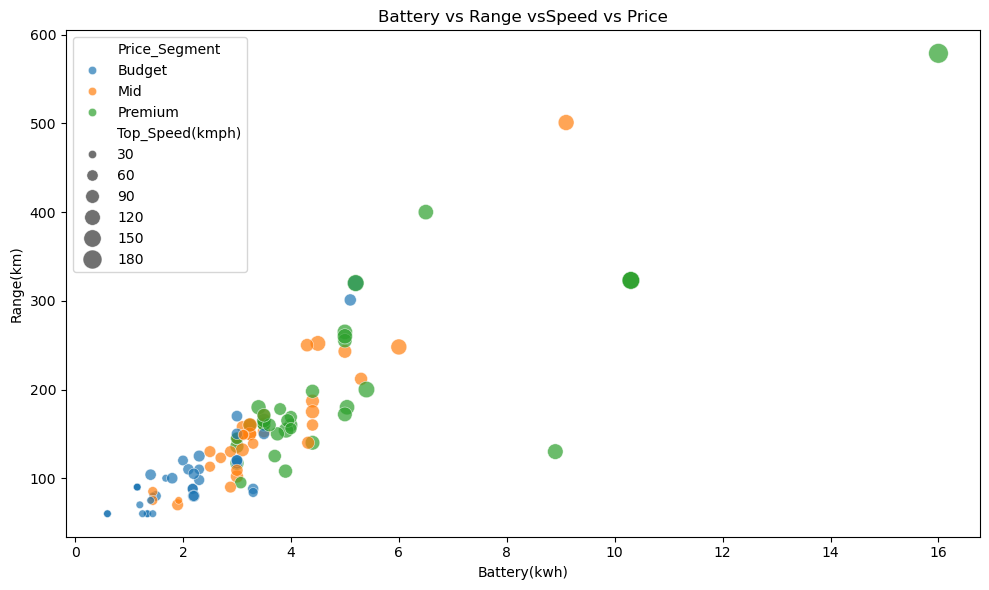

In [64]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Battery(kwh)',
    y='Range(km)',
    size='Top_Speed(kmph)',
    hue='Price_Segment',
    sizes=(30, 200),
    alpha=0.7
)

plt.title('Battery vs Range vsSpeed vs Price')
plt.tight_layout()
plt.show()

## Group-Based Analysis

In [65]:
brand_summary = (sub.groupby('Brand')
    .agg(bikes=('Model', 'count'),
         avg_price=('Price(Rs)', 'mean'),
         median_price=('Price(Rs)', 'median'),
         avg_speed=('Top_Speed(kmph)', 'mean'),
         avg_range=('Range(km)', 'mean'),
         avg_battery=('Battery(kwh)', 'mean'))
    .round(1).sort_values('median_price', ascending=False))

brand_summary.sort_values(by="bikes",ascending = False)

,bikes,avg_price,median_price,avg_speed,avg_range,avg_battery
Brand,,,,,,
Okinawa,8,101799.9,102930.0,51.4,111.1,2.8
OLA,7,120056.4,104999.0,128.4,360.1,7.3
Odysse,6,108420.5,100224.5,50.8,95.0,2.3
Ather,5,139888.2,130283.0,86.0,161.6,3.5
Revolt,4,121978.8,128969.5,82.5,155.0,3.2
BGauss,4,128490.0,128490.0,67.5,147.8,3.1
PURE EV,4,109904.5,102393.0,73.5,160.5,3.4
Ampere,4,98999.0,96999.0,62.0,120.8,2.4
Lectrix,4,81684.8,88494.5,49.8,98.8,2.4


In [66]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

In [67]:
num_cols = ['Price(Rs)','Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)']
(df.groupby('Price_Segment', observed=True)[num_cols].median().round(1))

,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh)
Price_Segment,,,,
Budget,79999.0,54.5,90.0,2.1
Mid,112496.5,70.0,149.5,3.2
Premium,165786.5,95.2,165.0,4.0


In [68]:
df.groupby("Range_Segment")["Price(Rs)"].mean()

Range_Segment
Low        95643.416667
Medium    166256.500000
High      158311.235294
Name: Price(Rs), dtype: float64

In [69]:
brand_summary = (df.groupby('Range_Segment')
    .agg(bikes=('Model', 'count'),
         avg_price=('Price(Rs)', 'mean'),
         median_price=('Price(Rs)', 'median'),
         avg_speed=('Top_Speed(kmph)', 'mean'),
         avg_range=('Range(km)', 'mean'),
         avg_battery=('Battery(kwh)', 'mean'))
    .round(1).sort_values('median_price', ascending=False))

brand_summary.sort_values(by="bikes",ascending = False)

,bikes,avg_price,median_price,avg_speed,avg_range,avg_battery
Range_Segment,,,,,,
Medium,38,166256.5,120230.5,76.7,142.4,3.4
Low,36,95643.4,80997.5,46.4,85.9,1.9
High,34,158311.2,149999.0,106.7,245.3,5.5


In [70]:
brand_summary = (df.groupby('Speed_Segment')
    .agg(bikes=('Model', 'count'),
         avg_price=('Price(Rs)', 'mean'),
         median_price=('Price(Rs)', 'median'),
         avg_speed=('Top_Speed(kmph)', 'mean'),
         avg_range=('Range(km)', 'mean'),
         avg_battery=('Battery(kwh)', 'mean'))
    .round(1).sort_values('median_price', ascending=False))

brand_summary.sort_values(by="bikes",ascending = False)

,bikes,avg_price,median_price,avg_speed,avg_range,avg_battery
Speed_Segment,,,,,,
Medium,41,122427.5,119450.0,76.8,152.5,3.5
Low,38,83167.6,83178.0,43.9,96.9,2.0
High,29,240124.0,182591.0,117.1,238.1,5.8


In [71]:
brand_summary = (df.groupby('Battery_Segment')
    .agg(bikes=('Model', 'count'),
         avg_price=('Price(Rs)', 'mean'),
         median_price=('Price(Rs)', 'median'),
         avg_speed=('Top_Speed(kmph)', 'mean'),
         avg_range=('Range(km)', 'mean'),
         avg_battery=('Battery(kwh)', 'mean'))
    .round(1).sort_values('median_price', ascending=False))

brand_summary.sort_values(by="bikes",ascending = False)

,bikes,avg_price,median_price,avg_speed,avg_range,avg_battery
Battery_Segment,,,,,,
Low,48,93447.0,87498.5,51.7,101.1,2.1
High,36,212295.6,156346.0,107.2,233.9,5.7
Medium,24,125641.4,122166.5,78.1,148.6,3.3


## Pivot Table Analysis

In [72]:
df.columns

Index(['Brand', 'Model', 'Rating', 'Rating_Members', 'Price(Rs)',
       'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)', 'Rating_Imputed',
       'Rating_Clean', 'Price_Segment', 'Range_Segment', 'Battery_Segment',
       'Speed_Segment'],
      dtype='object')

In [73]:
p = df.pivot_table(index='Brand', columns='Price_Segment', values='Model',
                     aggfunc='count', fill_value=0, observed=True)
p

Price_Segment,Budget,Mid,Premium
Brand,,,
Ampere,2,1,1
Ather,0,2,3
Avore,0,1,2
BGauss,0,2,2
BMW,0,0,2
Bajaj,0,2,0
Bounce Infinity,0,1,0
Evolet,2,0,0
Ferrato,0,0,1


In [74]:
top_10_brands = df['Brand'].value_counts().head(10).index


sub = df[df['Brand'].isin(top_10_brands)]

p = sub.pivot_table(index='Brand', columns='Battery_Segment', values='Range(km)',
                     aggfunc='mean', fill_value = 0,observed=True)
p

Battery_Segment,Low,Medium,High
Brand,,,
Ampere,120.750000,0.000000,0.000000
Ather,0.000000,161.600000,0.000000
BGauss,137.666667,0.000000,178.000000
Lectrix,98.750000,0.000000,0.000000
OLA,0.000000,0.000000,360.142857
OPG Mobility,78.333333,0.000000,160.000000
Odysse,76.250000,0.000000,132.500000
Okinawa,60.000000,128.166667,0.000000
PURE EV,150.000000,164.000000,0.000000


In [75]:
p = sub.pivot_table(index='Brand', columns='Speed_Segment', values='Battery(kwh)',
                     aggfunc='mean', fill_value = 0,observed=True)
p

Speed_Segment,Low,Medium,High
Brand,,,
Ampere,1.440000,2.65,3.000000
Ather,0.000000,3.50,3.500000
BGauss,2.850000,3.40,0.000000
Lectrix,2.213333,3.00,0.000000
OLA,0.000000,5.10,7.666667
OPG Mobility,1.800000,3.30,0.000000
Odysse,1.500000,4.01,0.000000
Okinawa,2.675714,3.60,0.000000
PURE EV,3.250000,3.50,3.500000


In [76]:
p = sub.pivot_table(index='Brand', columns='Speed_Segment', values='Range(km)',
                     aggfunc='mean', fill_value = 0,observed=True)
p

Speed_Segment,Low,Medium,High
Brand,,,
Ampere,80.000000,133.50,136.0
Ather,0.000000,160.75,165.0
BGauss,134.000000,161.50,0.0
Lectrix,92.666667,117.00,0.0
OLA,0.000000,301.00,370.0
OPG Mobility,77.500000,120.00,0.0
Odysse,76.250000,132.50,0.0
Okinawa,104.142857,160.00,0.0
PURE EV,150.000000,171.00,171.0


## Crosstab Analysis

In [77]:
pd.crosstab(df['Brand'], df['Price_Segment'], normalize='index').mul(100)

Price_Segment,Budget,Mid,Premium
Brand,,,
Ampere,50.000000,25.000000,25.000000
Ather,0.000000,40.000000,60.000000
Avore,0.000000,33.333333,66.666667
BGauss,0.000000,50.000000,50.000000
BMW,0.000000,0.000000,100.000000
Bajaj,0.000000,100.000000,0.000000
Bounce Infinity,0.000000,100.000000,0.000000
Evolet,100.000000,0.000000,0.000000
Ferrato,0.000000,0.000000,100.000000


In [78]:
pd.crosstab(df['Brand'], df['Speed_Segment'], normalize='index').mul(100)

Speed_Segment,Low,Medium,High
Brand,,,
Ampere,25.000000,50.000000,25.000000
Ather,0.000000,80.000000,20.000000
Avore,0.000000,0.000000,100.000000
BGauss,50.000000,50.000000,0.000000
BMW,0.000000,0.000000,100.000000
Bajaj,50.000000,50.000000,0.000000
Bounce Infinity,0.000000,100.000000,0.000000
Evolet,100.000000,0.000000,0.000000
Ferrato,0.000000,0.000000,100.000000


In [79]:
pd.crosstab(df['Brand'], df['Range_Segment'], normalize='index').mul(100)

Range_Segment,Low,Medium,High
Brand,,,
Ampere,25.000000,75.000000,0.000000
Ather,0.000000,20.000000,80.000000
Avore,0.000000,33.333333,66.666667
BGauss,0.000000,75.000000,25.000000
BMW,50.000000,50.000000,0.000000
Bajaj,50.000000,50.000000,0.000000
Bounce Infinity,100.000000,0.000000,0.000000
Evolet,100.000000,0.000000,0.000000
Ferrato,0.000000,0.000000,100.000000


In [80]:
pd.crosstab(df['Brand'], df['Battery_Segment'], normalize='index').mul(100)

Battery_Segment,Low,Medium,High
Brand,,,
Ampere,100.000000,0.000000,0.000000
Ather,0.000000,100.000000,0.000000
Avore,0.000000,33.333333,66.666667
BGauss,75.000000,0.000000,25.000000
BMW,0.000000,0.000000,100.000000
Bajaj,50.000000,50.000000,0.000000
Bounce Infinity,100.000000,0.000000,0.000000
Evolet,100.000000,0.000000,0.000000
Ferrato,0.000000,0.000000,100.000000


## Covariance & Correlation Analysis


In [81]:
num_cols = ['Price(Rs)', 'Top_Speed(kmph)', 'Range(km)', 'Battery(kwh)']

cov = df[num_cols].cov()
cov.round(1).map(lambda x:f"{x:.2f}")

,Price(Rs),Top_Speed(kmph),Range(km),Battery(kwh)
Price(Rs),22002684224.10,1963183.20,1900381.50,146556.30
Top_Speed(kmph),1963183.20,1081.90,2280.00,62.80
Range(km),1900381.50,2280.00,7429.30,166.50
Battery(kwh),146556.30,62.80,166.50,4.90


                 Price(Rs)  Top_Speed(kmph)  Range(km)  Battery(kwh)
Price(Rs)             1.00             0.40       0.15          0.45
Top_Speed(kmph)       0.40             1.00       0.80          0.86
Range(km)             0.15             0.80       1.00          0.87
Battery(kwh)          0.45             0.86       0.87          1.00


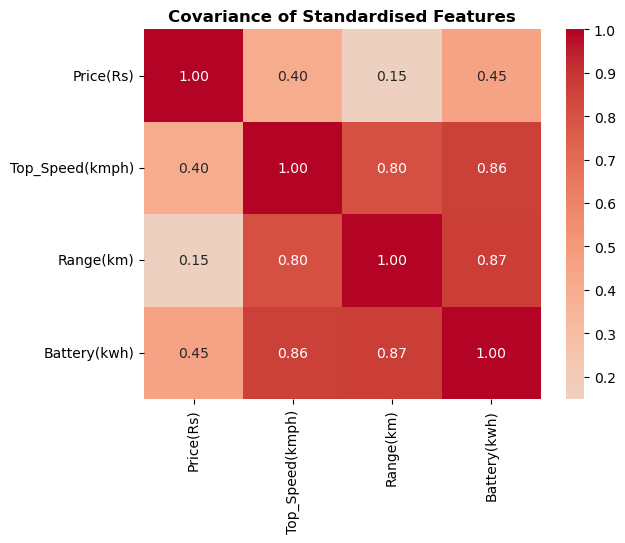

In [82]:



z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
print(z.cov().round(2))   # this equals the correlation matrix


sns.heatmap(z.cov(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Covariance of Standardised Features', fontweight='bold'); plt.show()